# IND320 Data to Decision - Compulsory work, part 4

Exchange rates from Norges Bank, time zones across the data sources, weekly weather per area,
sliding window correlation, forecasting of the reservoir filling with River, and the final structure
of the Streamlit app.

## Links

- **GitHub repository:** https://github.com/limmen20/limmen-streamlit-dashboard
- **Streamlit app:** https://limmen-app-dashboard.streamlit.app/
- **Screencast:** https://youtu.be/Cc8dlWIgZO4

## Feedback from part 3

The peer review and the teacher's feedback on part 3 were positive (tidy repository, complete notebook,
clear app). The structure from part 3 is kept and extended: notebooks in `notebooks/`, work on the
`testing` branch that is merged into `main` when finished, and the same commenting style.

## AI usage

I decided what the app should contain based on the task, set up and maintained the MongoDB Atlas database
and the Streamlit Cloud deployment, tested the pages, and checked the results and explanations in this
notebook. I used an AI assistant (Claude) as a coding helper: it helped me write and comment the code
(Norges Bank, time zones, weekly weather, sliding window correlation, River forecasting and the new app
structure), run the tests of the forecasting settings, word the findings and the log, and make the sketch
in section 8. The notebook was run from start to end, and the app was tested locally and on Streamlit
Cloud before the hand-in.

## Log

Section 8 shows a sketch of the app structure. The pages are now in three groups, Explore, Patterns & anomalies and Predict, and each page has a coloured header
with the name of its group, so it is clear where you are. The area is a global choice: it is set in the
sidebar or by clicking on the map, and it is kept in `st.session_state` so it follows the user between
pages. The month on the map is also shared, as the end of the training data on the Forecast page. The
two reservoir pages from part 3 were merged into one page with a plot tab and a table tab. The theme is
set in `.streamlit/config.toml`, and all charts are Plotly charts that follow it.

The map was the hardest part of the app. The GeoJSON outlines are made from the shapefiles from part 3.
At first clicking an area did nothing, because streamlit-folium did not return the clicked shape. Now
the page takes the clicked coordinates and finds the area that contains the point with shapely.

My biggest struggle was the weather data. The correlation and the forecast need 17 years of weekly
weather for 9 areas. The downloads hit open-meteo's limits per minute, per hour and finally per day, so I
rewrote the download to save each area in MongoDB as soon as it is finished and continue where it
stopped the next day. In the time zone investigation I found that open-meteo uses one fixed offset for
the whole answer, so summer hours are one hour off. Since Magasinstatistikk is weekly, I used Norwegian
weeks ending on Sunday as the common time axis for all sources.

For the forecast I chose weekly resolution, the resolution of the target. I tested 144 settings on all
9 areas and 4 forecast origins. The best settings were almost equal, so I chose the one with the smallest
worst error: SNARIMAX(2,1,0)(1,1,0) with season features and 10 years of history. Adding precipitation
lowered the mean error from 0.080 to 0.076 (the same week last year gives 0.118), so that is the default.
Temperature has the strongest correlation, but it did not improve the forecast, since it mostly follows
the season. One early forecast went below the lowest filling ever measured, so the forecast is now kept
inside the range of the training data.

The sliding window correlation showed that warm weeks give rising filling (+0.76), and that snowfall
gives higher filling 20–25 weeks later, when it melts. In NO2 the link was weaker in 2021, during the
energy crisis.

Bonus tasks: waiting time (a progress bar while the model trains, and caching of all downloads), error
handling (messages instead of crashes when an API or MongoDB fails, or data is missing) and a 90%
interval with quantile loss.

The feedback on part 3 was positive, so I kept the same structure, with a testing branch merged into main.

## 1. Setup

In [1]:
# Libraries
import io
import json
import math
import time
import tomllib
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pymongo import MongoClient
from river import linear_model, optim, preprocessing, time_series

# The notebook is in notebooks/, so the project folder is one level up
ROOT = Path.cwd().parent
with open(ROOT / ".streamlit" / "secrets.toml", "rb") as f:   # passwords, not on GitHub
    secrets = tomllib.load(f)
client = MongoClient(secrets["mongo"]["uri"])
db = client["ind320"]

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#888888"

## 2. Exchange rates from Norges Bank

Norges Bank has an open SDMX API without a key. The series `EXR/B.EUR+USD.NOK.SP` gives the daily
(business day) exchange rate of EUR and USD in NOK. With `format=csv` the answer is a semicolon-separated
table with one row per currency and date.

In [2]:
NB_API = "https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP"


def download_exchange_rates(start: str = "2010-01-01", end: str | None = None,
                            currencies=("EUR", "USD")) -> pd.DataFrame:
    """Daily exchange rates (NOK per unit) from Norges Bank, one column per currency."""
    params = {"format": "csv", "startPeriod": start, "locale": "en"}
    if end:
        params["endPeriod"] = end
    response = requests.get(NB_API.format(currencies="+".join(currencies)), params=params, timeout=60)
    response.raise_for_status()
    table = pd.read_csv(io.StringIO(response.text), sep=";")
    rates = table.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index)
    return rates.sort_index()


# Test: the last ten years
rates = download_exchange_rates("2016-01-01")
print("Rows:", len(rates), "| from", rates.index[0].date(), "to", rates.index[-1].date())
rates.tail()

Rows: 2745 | from 2016-01-04 to 2026-11-26


BASE_CUR,EUR,USD
TIME_PERIOD,,
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076
2026-11-24,10.7350,9.7920
2026-11-25,10.7778,9.8562
2026-11-26,10.7180,9.7658


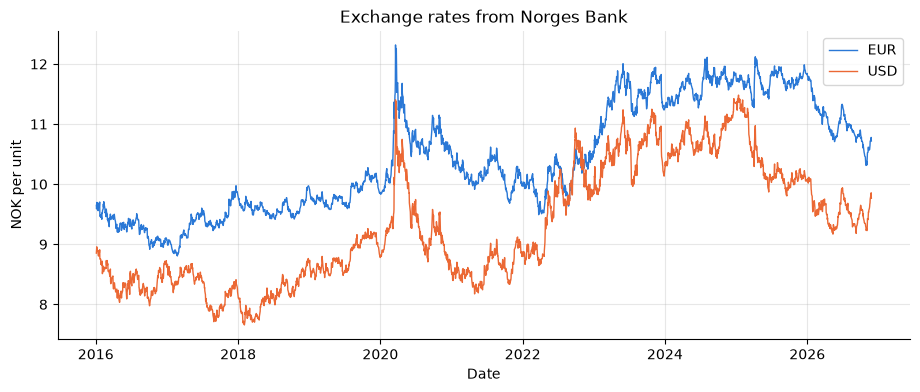

In [3]:
fig, ax = plt.subplots()
ax.plot(rates.index, rates["EUR"], color=BLUE, linewidth=1, label="EUR")
ax.plot(rates.index, rates["USD"], color=ORANGE, linewidth=1, label="USD")
ax.set_title("Exchange rates from Norges Bank")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per unit")
ax.legend()
plt.show()

## 3. Time zones in the data sources

Each source handles time differently. Below, each one is checked with a small request.

### 3.1 Magasinstatistikk (NVE)

In [4]:
NVE_API = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
latest = pd.DataFrame(requests.get(f"{NVE_API}/HentOffentligDataSisteUke", timeout=60).json())
print(latest[["dato_Id", "iso_aar", "iso_uke", "neste_Publiseringsdato"]].head(2).to_string(index=False))
print("Weekday of dato_Id:", pd.to_datetime(latest["dato_Id"]).dt.day_name().unique())

   dato_Id  iso_aar  iso_uke neste_Publiseringsdato
2026-11-22     2026       47    2026-12-02T13:00:00
2026-11-22     2026       47    2026-12-02T13:00:00
Weekday of dato_Id: <ArrowStringArray>
['Sunday']
Length: 1, dtype: str


`dato_Id` is a date without a time, and it is always the **Sunday** that ends the ISO week. The next
publication time (`13:00`) has no offset, so it is Norwegian local time.

### 3.2 ENTSO-E (via Energy-Charts)

In [5]:
# ENTSO-E's API takes and returns times in UTC (periodStart/periodEnd as yyyyMMddHHmm UTC).
# I still have no ENTSO-E token, so Energy-Charts (which republishes the ENTSO-E flows) is used here.
ec = requests.get("https://api.energy-charts.info/cbpf",
                  params={"country": "no", "start": "2025-03-30", "end": "2025-03-30"}, timeout=60).json()
t = pd.to_datetime(ec["unix_seconds"], unit="s", utc=True)
print("First value (UTC):", t[0], "-> Norwegian time:", t[0].tz_convert("Europe/Oslo"))
print("Values on the day daylight saving time starts:", len(t), "quarter-hours (23 hours, not 24)")

First value (UTC): 2025-03-29 23:00:00+00:00 -> Norwegian time: 2025-03-30 00:00:00+01:00
Values on the day daylight saving time starts: 92 quarter-hours (23 hours, not 24)


### 3.3 open-meteo

In [6]:
# Three days around the start of daylight saving time (30 March 2025): hourly temperature in Oslo,
# once in GMT (UTC) and once with timezone=Europe/Oslo
params = {"latitude": 59.91, "longitude": 10.75, "start_date": "2025-03-29", "end_date": "2025-03-31",
          "hourly": "temperature_2m", "models": "era5"}
answers = {tz: requests.get("https://archive-api.open-meteo.com/v1/archive", params={**params, "timezone": tz},
                            timeout=60).json() for tz in ["GMT", "Europe/Oslo"]}
for tz, answer in answers.items():
    print(f"{tz:12s} utc_offset_seconds={answer['utc_offset_seconds']:5d} | hours: {len(answer['hourly']['time'])}")

gmt = pd.Series(answers["GMT"]["hourly"]["temperature_2m"], index=pd.to_datetime(answers["GMT"]["hourly"]["time"]))
oslo = pd.Series(answers["Europe/Oslo"]["hourly"]["temperature_2m"],
                 index=pd.to_datetime(answers["Europe/Oslo"]["hourly"]["time"]))
print("Oslo values = GMT values one hour earlier, for all hours:",
      bool((oslo.iloc[1:].to_numpy() == gmt.iloc[:-1].to_numpy()).all()))

# Which real Norwegian time does each label stand for?
utc = oslo.index - pd.Timedelta(seconds=answers["Europe/Oslo"]["utc_offset_seconds"])
real = utc.tz_localize("UTC").tz_convert("Europe/Oslo").tz_localize(None)
print(pd.DataFrame({"label from open-meteo": oslo.index, "real Norwegian time": real}).iloc[[24, 26, 27, 60]]
      .to_string(index=False))

GMT          utc_offset_seconds=    0 | hours: 72
Europe/Oslo  utc_offset_seconds= 3600 | hours: 72
Oslo values = GMT values one hour earlier, for all hours: True
label from open-meteo real Norwegian time
  2025-03-30 00:00:00 2025-03-30 00:00:00
  2025-03-30 02:00:00 2025-03-30 03:00:00
  2025-03-30 03:00:00 2025-03-30 04:00:00
  2025-03-31 12:00:00 2025-03-31 13:00:00


open-meteo returns **UTC by default** (`timezone=GMT`). With `timezone=Europe/Oslo` the whole answer gets
**one fixed offset** (`utc_offset_seconds`, +1 hour here, the offset at the start of the period). There is
no jump when daylight saving time starts: three days still give 72 hours, and from 30 March the labels are
one hour behind the real Norwegian (summer) time. For hourly analysis UTC is therefore the safer choice.
For daily values the shift is at most one hour per day (in summer a "day" runs from 01:00 to 01:00), which
does not matter for weekly sums and means.

### 3.4 Norges Bank

In [7]:
around_christmas = download_exchange_rates("2025-12-20", "2026-01-05", currencies=("EUR",))
print(around_christmas)
print("Weekdays present:", sorted(around_christmas.index.day_name().unique()))

BASE_CUR         EUR
TIME_PERIOD         
2025-12-22   11.8875
2025-12-23   11.8490
2025-12-29   11.8270
2025-12-30   11.8260
2025-12-31   11.8430
2026-01-02   11.7985
2026-01-05   11.7795
Weekdays present: ['Friday', 'Monday', 'Tuesday', 'Wednesday']


Norges Bank publishes **one value per business day** (dates without time, fixed at 14:15 Norwegian
time). Weekends and holidays are missing.

### 3.5 Findings and solutions

| Source | Time stamps | Problem | Solution in this project |
|---|---|---|---|
| Magasinstatistikk | Date only, Sunday that ends the ISO week | Weekly, not daily | Weekly resolution, weeks ending on Sunday (`W-SUN`) |
| ENTSO-E | UTC (also via Energy-Charts) | DST days have 23/25 hours locally | Store in UTC, convert to `Europe/Oslo` before making daily totals (part 2) |
| open-meteo | UTC by default, local time on request | Local time uses one fixed offset per answer, so summer hours are 1 h off | Hourly data in UTC (SPC/LOF), daily data with `Europe/Oslo` (at most 1 h off, irrelevant for weekly values) |
| Norges Bank | Business-day dates, 14:15 local time | Gaps on weekends/holidays | Weekly mean over the business days (same `W-SUN` weeks) |

So the common time axis for combining the sources is **Norwegian weeks ending on Sunday**, which is
exactly the resolution of Magasinstatistikk.

## 4. GeoJSON for the map

The shapefiles from part 3 are converted to GeoJSON, which the folium map in the app reads directly.
One file per area type in Magasinstatistikk (NO, EL price areas, VASS water areas). The outlines are
simplified (500 m tolerance in UTM 33) so the files are small and the map loads fast.

In [8]:
el = gpd.read_file(ROOT / "data/shapefiles/elspot_areas.shp").set_index("ElSpotOmr").geometry
rg = gpd.read_file(ROOT / "data/shapefiles/nve_regions.shp").set_index("REGION").geometry
rows = [("NO", "NO", 0, "Norway (total)", el.union_all())]
rows += [(f"NO{i}", "EL", i, f"NO{i}", el[f"NO{i}"]) for i in range(1, 6)]
rows += [("VASS1", "VASS", 1, "Watercourse region 1", rg[["RØ", "RS"]].union_all()),   # east = RØ + RS
         ("VASS2", "VASS", 2, "Watercourse region 2", rg["RV"]),                         # west
         ("VASS3", "VASS", 3, "Watercourse region 3", rg[["RM", "RN"]].union_all())]   # north = RM + RN
areas = gpd.GeoDataFrame(rows, columns=["region", "area_type", "area_number", "name", "geometry"], crs=4326)
areas["geometry"] = areas.to_crs(25833).simplify(500).to_crs(4326)

out = ROOT / "data" / "geojson"
out.mkdir(parents=True, exist_ok=True)
for area_type, name in [("NO", "country"), ("EL", "price_areas"), ("VASS", "water_areas")]:
    path = out / f"{name}.geojson"
    areas[areas["area_type"] == area_type].to_file(path, driver="GeoJSON")
    print(f"{path.name:20s} {path.stat().st_size / 1e3:6.0f} kB")

country.geojson         208 kB
price_areas.geojson     240 kB
water_areas.geojson      77 kB


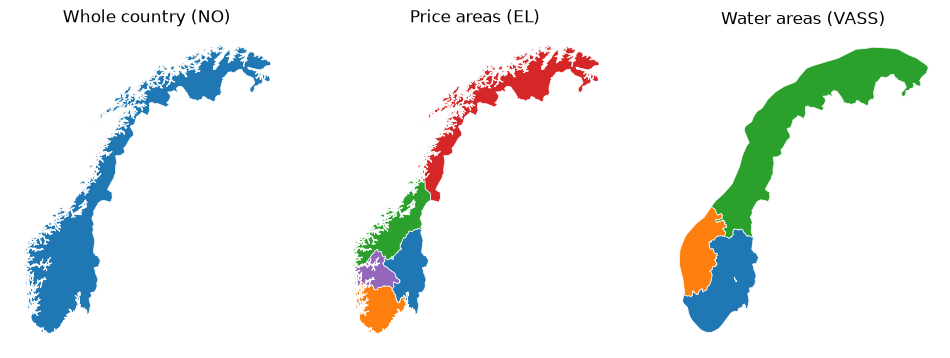

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
for ax, (name, title) in zip(axes, [("country", "Whole country (NO)"), ("price_areas", "Price areas (EL)"),
                                    ("water_areas", "Water areas (VASS)")]):
    gpd.read_file(ROOT / "data" / "geojson" / f"{name}.geojson").plot(ax=ax, column="region", cmap="tab10",
                                                                       edgecolor="white", linewidth=0.5)
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## 5. Weekly weather per area

The correlation and forecasting need many years of weather, aggregated to the same weeks as
Magasinstatistikk. Downloading years of hourly data live in the app would be slow and quickly hit
open-meteo's limits (600 calls per minute, 5000 per hour and 10 000 per day for the free API; a long
daily download for five locations counts as more than a thousand calls). So the weekly weather is made
here and stored in MongoDB:

- daily ERA5 data in Norwegian time (`timezone=Europe/Oslo`) from 2010, for 5 of the 1000 random
  locations per area (from part 3), averaged per day,
- weekly mean temperature and wind, weekly sums of precipitation, rain and snowfall (weeks ending on
  Sunday), only complete weeks.

Areas that are already in MongoDB are skipped, so the notebook can be re-run without new downloads.

In [10]:
DAILY = {"temperature_2m_mean": "temperature", "precipitation_sum": "precipitation", "rain_sum": "rain",
         "snowfall_sum": "snowfall", "wind_speed_10m_max": "wind_speed"}
locations = {d["region"]: d["locations"] for d in db["region_locations"].find({}, {"_id": 0})}
weather_collection = db["weather_weekly"]


def download_weekly_weather(region: str, start: str = "2010-01-01", end: str = "2026-11-15",
                            n_locations: int = 5, seed: int = 1) -> pd.DataFrame:
    """Weekly weather for one area: average of n random locations, weeks ending on Sunday."""
    pairs = locations[region]
    rng = np.random.default_rng(seed)
    chosen = [pairs[i] for i in rng.choice(len(pairs), size=n_locations, replace=False)]
    params = {"latitude": ",".join(str(lat) for lon, lat in chosen),
              "longitude": ",".join(str(lon) for lon, lat in chosen),
              "start_date": start, "end_date": end, "daily": ",".join(DAILY), "models": "era5",
              "timezone": "Europe/Oslo"}
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=300)
    response.raise_for_status()
    daily = pd.concat([pd.DataFrame(r["daily"]) for r in response.json()]).rename(columns=DAILY)
    daily["time"] = pd.to_datetime(daily["time"])
    daily = daily.groupby("time").mean()                                # area average per day
    weekly = daily.resample("W-SUN").agg({"temperature": "mean", "precipitation": "sum", "rain": "sum",
                                          "snowfall": "sum", "wind_speed": "mean"})
    weekly = weekly[daily.resample("W-SUN").size() == 7]                # only complete weeks
    return weekly.reset_index().rename(columns={"time": "week"}).assign(region=region)


for region in locations:
    if weather_collection.count_documents({"region": region}) > 0:
        continue                                                        # already stored
    weekly = download_weekly_weather(region)
    weather_collection.insert_many(weekly.to_dict("records"))
    print(region, len(weekly), "weeks stored")

weather = pd.DataFrame(list(weather_collection.find({}, {"_id": 0})))
print("Areas:", sorted(weather["region"].unique()), "| weeks per area:", weather.groupby("region").size().iloc[0])
weather.groupby("region")[["temperature", "precipitation", "snowfall"]].mean().round(2)

Areas: ['NO', 'NO1', 'NO2', 'NO3', 'NO4', 'NO5', 'VASS1', 'VASS2', 'VASS3'] | weeks per area: 880


,temperature,precipitation,snowfall
region,,,
NO,6.89,23.48,2.08
NO1,5.59,17.06,2.34
NO2,5.68,27.40,2.66
NO3,4.86,30.65,5.39
NO4,1.81,22.00,5.82
NO5,2.58,39.92,8.13
VASS1,5.90,29.31,3.80
VASS2,5.30,43.39,4.06
VASS3,2.12,22.58,4.42


## 6. Sliding window correlation (weather vs. reservoir)

As in the book: the weather series is shifted by a lag (weather leads), and `rolling(window).corr()`
gives the correlation inside a sliding window. The reservoir variable is the **weekly change in filling**,
since it reacts to inflow more directly than the level itself.

In [11]:
# Weekly filling for every area (same renaming as before)
res = pd.DataFrame(requests.get(f"{NVE_API}/HentOffentligData", timeout=60).json())
res["date"] = pd.to_datetime(res["dato_Id"])
filling = {("NO" if t == "NO" else f"NO{n}" if t == "EL" else f"VASS{n}"):
           g.set_index("date")["fyllingsgrad"].sort_index().asfreq("W-SUN").interpolate()
           for (t, n), g in res.groupby(["omrType", "omrnr"])}


def lagged_correlation(region: str, prop: str, lag: int) -> float:
    """Correlation between the weekly change in filling and a weather property `lag` weeks earlier."""
    y = filling[region].diff()
    w = weather[weather["region"] == region].set_index("week")[prop]
    w.index = w.index + pd.Timedelta(weeks=lag)                         # shift = weather leads
    return y.corr(w.reindex(y.index))


props = ["temperature", "precipitation", "rain", "snowfall", "wind_speed"]
lag_table = pd.DataFrame({prop: [lagged_correlation("NO", prop, lag) for lag in range(0, 27, 2)] for prop in props},
                         index=pd.Index(range(0, 27, 2), name="lag (weeks)"))
lag_table.round(2)

,temperature,precipitation,rain,snowfall,wind_speed
lag (weeks),,,,,
0,0.76,0.23,0.40,-0.51,0.02
2,0.61,-0.00,0.16,-0.46,-0.15
4,0.51,-0.07,0.07,-0.39,-0.11
6,0.39,-0.14,-0.02,-0.33,-0.14
8,0.25,-0.17,-0.09,-0.22,-0.10
10,0.11,-0.18,-0.14,-0.10,0.01
12,-0.02,-0.18,-0.19,0.05,0.04
14,-0.18,-0.17,-0.23,0.19,0.05
16,-0.33,-0.18,-0.29,0.32,0.11


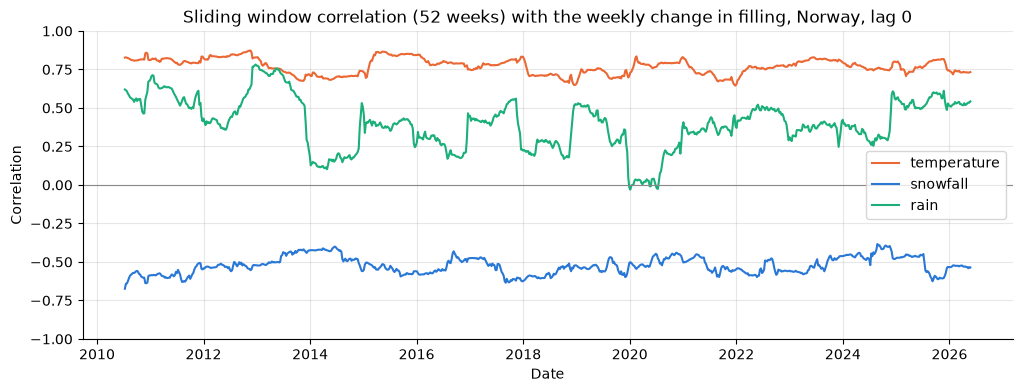

In [12]:
def sliding_window_correlation(region: str, prop: str, lag: int = 0, window: int = 52) -> pd.Series:
    """Sliding window correlation, as in the book (centered rolling window)."""
    y = filling[region].diff()
    w = weather[weather["region"] == region].set_index("week")[prop]
    w.index = w.index + pd.Timedelta(weeks=lag)
    data = pd.concat([y, w], axis=1).dropna()
    return data.iloc[:, 0].rolling(window, center=True).corr(data.iloc[:, 1])


fig, ax = plt.subplots(figsize=(12, 4))
for prop, color in [("temperature", ORANGE), ("snowfall", BLUE), ("rain", GREEN)]:
    swc = sliding_window_correlation("NO", prop, lag=0, window=52)
    ax.plot(swc.index, swc, color=color, linewidth=1.5, label=prop)
ax.axhline(0, color=GREY, linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_title("Sliding window correlation (52 weeks) with the weekly change in filling, Norway, lag 0")
ax.set_xlabel("Date")
ax.set_ylabel("Correlation")
ax.legend()
plt.show()

In [13]:
# Yearly mean of the 52-week correlation with temperature (lag 0) in some areas
yearly = pd.DataFrame({region: sliding_window_correlation(region, "temperature").groupby(lambda d: d.year).mean()
                       for region in ["NO", "NO1", "NO2", "NO4", "NO5"]})
yearly.loc[2011:2025].round(2)

,NO,NO1,NO2,NO4,NO5
2011,0.80,0.68,0.79,0.75,0.78
2012,0.84,0.74,0.82,0.82,0.84
2013,0.74,0.52,0.69,0.75,0.78
2014,0.71,0.56,0.67,0.71,0.71
2015,0.83,0.76,0.81,0.79,0.81
2016,0.79,0.70,0.73,0.82,0.81
2017,0.79,0.64,0.69,0.80,0.78
2018,0.71,0.54,0.61,0.73,0.75
2019,0.72,0.57,0.66,0.69,0.71
2020,0.79,0.69,0.73,0.79,0.78


In [14]:
# Strongest lag (0-26 weeks) per area for snowfall and rain
lags = range(0, 27)
strongest = {}
for region in filling:
    for prop in ["snowfall", "rain"]:
        corr = pd.Series({lag: lagged_correlation(region, prop, lag) for lag in lags})
        strongest[(region, prop)] = f"{corr.max():+.2f} at {corr.idxmax()} weeks"
pd.Series(strongest).unstack()

,rain,snowfall
NO,+0.40 at 0 weeks,+0.52 at 21 weeks
NO1,+0.44 at 0 weeks,+0.44 at 21 weeks
NO2,+0.46 at 0 weeks,+0.40 at 21 weeks
NO3,+0.42 at 0 weeks,+0.47 at 20 weeks
NO4,+0.52 at 0 weeks,+0.46 at 23 weeks
NO5,+0.47 at 0 weeks,+0.52 at 25 weeks
VASS1,+0.38 at 0 weeks,+0.50 at 21 weeks
VASS2,+0.40 at 0 weeks,+0.53 at 25 weeks
VASS3,+0.39 at 0 weeks,+0.49 at 23 weeks


**Findings**

- **Temperature** has the strongest link with the weekly change in filling: +0.76 at lag 0 for Norway.
  Warm weeks are melting weeks with a lot of inflow. With a long lag the sign turns (−0.67 at 24–26
  weeks), because a warm week half a year earlier belongs to the opposite season.
- **Snowfall** is negative at lag 0 (−0.51), since snow is stored on the ground instead of flowing into
  the reservoirs. 20–25 weeks later it is positive in every area (+0.40 to +0.53), when the snow melts.
  This is the clearest leading signal; the delay is longest in the west and north (25 weeks in NO5 and
  VASS2).
- **Rain** works directly: the strongest lag is 0 weeks in all areas (+0.38 to +0.52, highest in NO4).
  **Precipitation** as a whole is weaker (+0.23), because it mixes rain (inflow now) with snow (inflow
  months later). **Wind** has almost no correlation.
- In the 52-week sliding window the temperature correlation is stable for Norway as a whole (0.71–0.84
  per year). In the south it varies more: in NO2 it drops to 0.55 in 2021 and 0.61 in 2018 and 2025,
  and NO1 has years around 0.52–0.56. 2018 was a very dry year in southern Norway, and 2021–2022 were the
  years of the energy crisis with record prices in the south, when the use of the reservoirs depended
  more on prices than on the weather. A weaker weather link in those years fits with that.

## 7. Forecasting the reservoir filling with River (SNARIMAX)

**Time resolution: weekly.** Magasinstatistikk is weekly, so a finer resolution would not add
information about the target, only more steps: daily data would give 7 times as many samples (and a
season length of 365), and River learns one sample at a time in pure Python. With weekly data ten years
are about 520 samples, and one model trains in well under a second, so many settings can be tested.

The function below takes the area, the end of the training data, the length of the history, the horizon,
the SNARIMAX orders, the learning rate and the data sources (season features, weather properties and
exchange rates) as inputs. Future inputs are not known when forecasting: weather uses the average for the
same week of the year in the training period (climatology), exchange rates keep their last value.
The forecast is dynamic, each step builds on the forecasts for the steps before.

In [15]:
WEATHER_INPUTS = ["temperature", "precipitation", "rain", "snowfall", "wind_speed"]
CURRENCY_INPUTS = ["EUR", "USD"]
weekly_rates = download_exchange_rates("2010-01-01").resample("W-SUN").mean()   # same weeks as the reservoirs


def season_features(date) -> dict:
    """Smooth distance from the date to each month (as in the book's SNARIMAX example)."""
    month = date.month + (date.day - 1) / 31
    return {f"season_m{m}": math.exp(-((month - m) ** 2)) for m in range(1, 13)}


def make_model(p, d, q, sp, sd, sq, learning_rate, quantile=None):
    """SNARIMAX with season length 52 weeks; quantile loss gives a model for a quantile instead of the mean."""
    loss = optim.losses.Quantile(quantile) if quantile is not None else optim.losses.Squared()
    regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(
        optimizer=optim.SGD(learning_rate), intercept_lr=0.1, loss=loss)
    return time_series.SNARIMAX(p=p, d=d, q=q, m=52, sp=sp, sd=sd, sq=sq, regressor=regressor)


def forecast_filling(region: str = "NO", train_end: str = "2025-10-26", history_years: int = 10,
                     horizon: int = 26, p: int = 2, d: int = 1, q: int = 0, sp: int = 1, sd: int = 1, sq: int = 0,
                     learning_rate: float = 0.01, inputs=("season",), interval: bool = False,
                     known_future: bool = False) -> pd.DataFrame:
    """Dynamic forecast of the weekly filling ratio for one area. Returns forecast (+ interval) and actual.

    known_future=True uses the observed weather/exchange rates for the forecast weeks. That is only
    possible afterwards and is used to test how much the inputs could help at best.
    """
    target = filling[region]
    end = pd.Timestamp(train_end)
    train = target[(target.index > end - pd.DateOffset(years=history_years)) & (target.index <= end)]
    future_index = pd.date_range(train.index[-1] + pd.Timedelta(weeks=1), periods=horizon, freq="W-SUN")

    # Exogenous inputs for the training weeks and the future weeks
    exog = pd.DataFrame(index=train.index.union(future_index))
    w_cols = [i for i in inputs if i in WEATHER_INPUTS]
    c_cols = [i for i in inputs if i in CURRENCY_INPUTS]
    if w_cols:
        exog = exog.join(weather[weather["region"] == region].set_index("week")[w_cols])
    if c_cols:
        exog = exog.join(weekly_rates[c_cols])
    known = exog.loc[train.index].ffill().bfill()
    week = known.index.isocalendar().week.to_numpy()
    if not known_future:
        for col in w_cols:     # future weather = average for the same week of the year (climatology)
            climate = known[col].groupby(week).mean()
            exog.loc[future_index, col] = climate.reindex(future_index.isocalendar().week.to_numpy()).to_numpy()
        for col in c_cols:     # future exchange rate = last known value
            exog.loc[future_index, col] = known[col].iloc[-1]
    exog.loc[train.index] = known

    def x_for(date):
        x = season_features(date) if "season" in inputs else {}
        x.update({c: float(exog.at[date, c]) for c in w_cols + c_cols})
        return x or None

    models = [make_model(p, d, q, sp, sd, sq, learning_rate, qt) for qt in ([None, 0.05, 0.95] if interval else [None])]
    for date, y in train.items():
        for model in models:
            model.learn_one(y, x=x_for(date))
    xs = [x_for(date) for date in future_index]
    xs = None if all(x is None for x in xs) else xs
    result = pd.DataFrame(index=future_index)
    for name, model in zip(["forecast", "lower", "upper"], models):
        # never below/above the lowest/highest filling in the training data (see the tests below)
        result[name] = np.clip(model.forecast(horizon=horizon, xs=xs), train.min(), train.max())
    result["actual"] = target.reindex(future_index)
    return result


# Quick test: Norway, training until the end of October 2025, 26 weeks ahead
example = forecast_filling("NO", "2025-10-26")
print("Mean absolute error:", round((example["forecast"] - example["actual"]).abs().mean(), 3))
example.head()

Mean absolute error: 0.042


,forecast,actual
2025-11-02,0.818813,0.800029
2025-11-09,0.822344,0.811659
2025-11-16,0.815090,0.805887
2025-11-23,0.799800,0.777205
2025-11-30,0.783797,0.757982


### 7.1 Testing the settings

Every setting is tested on **all 9 areas** and **4 forecast origins** (end of October 2022, 2023 and
2024, when the reservoirs are full, and end of April 2025, when they are nearly empty), 26 weeks ahead.
The score is the mean absolute error of the filling ratio. As a baseline, "the same week last year"
(seasonal naive) is used.

In [16]:
ORIGINS = ["2022-10-30", "2023-10-29", "2024-10-27", "2025-04-27"]


def evaluate(**settings) -> tuple[float, float]:
    """Mean and worst absolute error over all areas and origins for one setting."""
    errors = []
    for region in filling:
        for origin in ORIGINS:
            r = forecast_filling(region, origin, **settings)
            errors.append((r["forecast"] - r["actual"]).abs().mean())
    return float(np.mean(errors)), float(np.max(errors))


def seasonal_naive_error(horizon: int = 26) -> float:
    errors = []
    for s in filling.values():
        for origin in ORIGINS:
            future = s[s.index > pd.Timestamp(origin)][:horizon]
            last_year = s.reindex(future.index - pd.Timedelta(weeks=52)).to_numpy()
            errors.append(np.mean(np.abs(future.to_numpy() - last_year)))
    return float(np.mean(errors))


start = time.time()
orders = [(1, 0, 0, 0, 0, 0), (1, 0, 0, 1, 1, 0), (2, 0, 0, 1, 1, 0), (2, 1, 0, 1, 1, 0), (2, 1, 1, 1, 1, 0),
          (1, 0, 0, 1, 1, 1), (3, 0, 0, 1, 1, 0), (1, 1, 0, 0, 1, 0)]
rows = []
for (p, d, q, sp, sd, sq) in orders:
    for season in [True, False]:
        for history in [5, 10, 15]:
            for lr in [0.005, 0.01, 0.02]:
                mean_err, worst = evaluate(p=p, d=d, q=q, sp=sp, sd=sd, sq=sq, history_years=history,
                                           learning_rate=lr, inputs=("season",) if season else ())
                rows.append(dict(p=p, d=d, q=q, sp=sp, sd=sd, sq=sq, season=season, history=history, lr=lr,
                                 mae=mean_err, worst=worst))
grid = pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)
print(f"{len(grid)} settings x {len(filling) * len(ORIGINS)} forecasts in {time.time() - start:.0f} s")
print("Seasonal naive (same week last year):", round(seasonal_naive_error(), 4))
grid.head(10).round(4)

144 settings x 36 forecasts in 41 s
Seasonal naive (same week last year): 0.1182


,p,d,q,sp,sd,sq,season,history,lr,mae,worst
0,2,1,1,1,1,0,False,10,0.005,0.0782,0.2879
1,2,1,1,1,1,0,False,15,0.005,0.0786,0.2882
2,2,1,1,1,1,0,False,5,0.020,0.0787,0.2855
3,2,1,0,1,1,0,True,10,0.005,0.0790,0.2180
4,2,1,1,1,1,0,True,10,0.005,0.0790,0.2179
5,2,1,1,1,1,0,False,10,0.010,0.0793,0.2864
6,2,1,1,1,1,0,True,10,0.010,0.0799,0.2041
7,2,1,0,1,1,0,True,10,0.010,0.0799,0.2041
8,2,1,1,1,1,0,False,5,0.010,0.0800,0.2867
9,2,1,1,1,1,0,False,15,0.010,0.0802,0.2862


The ten best settings have almost the same mean error (within about 0.002, much less than the
difference between areas and years). Among them I choose the one with the **smallest worst error**, and
if that is a tie, the simplest model (fewest AR/MA terms). A forecast that is occasionally far off is
worse for a user than a tiny gain in the average.

In [17]:
top = grid.head(10).assign(worst_rounded=lambda t: t["worst"].round(3),
                           terms=lambda t: t["p"] + t["q"] + t["sp"] + t["sq"])
best = top.sort_values(["worst_rounded", "terms", "mae"]).iloc[0]
print("Chosen setting:")
print(best[["p", "d", "q", "sp", "sd", "sq", "season", "history", "lr", "mae", "worst"]].to_string())

Chosen setting:
p                 2
d                 1
q                 0
sp                1
sd                1
sq                0
season         True
history          10
lr             0.01
mae        0.079939
worst       0.20414


In [18]:
# Effect of the history length and of the season features (chosen orders only)
same_orders = grid[(grid[["p", "d", "q", "sp", "sd", "sq"]] == best[["p", "d", "q", "sp", "sd", "sq"]]).all(axis=1)]
same_orders.pivot_table(index="history", columns="season", values="mae", aggfunc="min").round(4)

season,False,True
history,,
5,0.0815,0.0886
10,0.0813,0.0790
15,0.0813,0.0814


In [19]:
# How the error grows with the horizon (chosen setting)
best_settings = dict(p=int(best.p), d=int(best.d), q=int(best.q), sp=int(best.sp), sd=int(best.sd), sq=int(best.sq),
                     history_years=int(best.history), learning_rate=float(best.lr),
                     inputs=("season",) if best.season else ())
pd.DataFrame({h: evaluate(horizon=h, **best_settings) for h in [4, 13, 26, 52]},
             index=["mean error", "worst error"]).round(4)

,4,13,26,52
mean error,0.0375,0.0665,0.0799,0.1312
worst error,0.1267,0.2159,0.2041,0.2775


### 7.2 Data sources (exogenous inputs)

One source at a time is added to the chosen setting. Each is tested twice: as in a real forecast
(climatology for the weather, last value for the exchange rates), and with the **observed** future values.
The second is not possible in practice, but shows how much the source could help at best.

In [20]:
base = tuple(best_settings["inputs"])
sources = {"season only" if base else "no inputs": base}
sources.update({f"+ {s}": base + (s,) for s in WEATHER_INPUTS + CURRENCY_INPUTS})
sources["+ temperature + snowfall"] = base + ("temperature", "snowfall")
source_table = pd.DataFrame({
    name: [*evaluate(**{**best_settings, "inputs": inp}), evaluate(**{**best_settings, "inputs": inp}, known_future=True)[0]]
    for name, inp in sources.items()}, index=["mean error", "worst error", "mean error, observed future inputs"]).T
source_table.sort_values("mean error").round(4)

,mean error,worst error,"mean error, observed future inputs"
+ precipitation,0.0758,0.2067,0.0760
+ temperature + snowfall,0.0767,0.2034,0.0812
+ rain,0.0772,0.1993,0.0780
+ snowfall,0.0783,0.2123,0.0772
season only,0.0799,0.2041,0.0799
+ temperature,0.0802,0.1954,0.0832
+ wind_speed,0.0810,0.2103,0.0831
+ EUR,0.0872,0.1719,0.0859
+ USD,0.0917,0.1703,0.0876


**Findings**

- **Precipitation** helps a little: the mean error goes from 0.080 to 0.076, and the worst error stays
  about the same. With the *observed* future precipitation the error is the same, so the gain does not
  come from knowing the weather ahead. Precipitation explains part of the weekly changes in the training
  data, so the other terms of the model are fitted with less noise. Rain and snowfall give a similar,
  smaller gain.
- **Temperature** does not help, even though it has the strongest correlation in section 6. It follows
  the season so closely that it adds little to the season features, and even the observed future
  temperature makes the error a bit higher.
- The **exchange rates** make the mean error clearly higher (0.087 and 0.092). They have no direct
  link to the weekly inflow, and in the forecast they are kept at their last value.
- Default in the app: the chosen setting with **season + precipitation**.

In [21]:
# The default on the Forecast page (forecasting.DEFAULTS)
default_settings = {**best_settings, "inputs": ("season", "precipitation")}
default_settings

{'p': 2,
 'd': 1,
 'q': 0,
 'sp': 1,
 'sd': 1,
 'sq': 0,
 'history_years': 10,
 'learning_rate': 0.01,
 'inputs': ('season', 'precipitation')}

### 7.3 Confidence interval with quantile loss (bonus)

Two extra models are trained with `optim.losses.Quantile(0.05)` and `Quantile(0.95)`, which gives a 90%
interval. The coverage (share of actual values inside the interval) is checked on the same test set.

In [22]:
coverage, width = [], []
for region in filling:
    for origin in ORIGINS:
        r = forecast_filling(region, origin, interval=True, **default_settings)
        coverage.append(((r["actual"] >= r["lower"]) & (r["actual"] <= r["upper"])).mean())
        width.append((r["upper"] - r["lower"]).mean())
print(f"Coverage of the 90% interval: {np.mean(coverage):.0%} | mean width: {np.mean(width):.2f} (filling ratio)")

Coverage of the 90% interval: 92% | mean width: 0.65 (filling ratio)


The interval covers 92% of the actual values, close to the 90% it should, but it is very wide (0.65 on
average). The quantile models also forecast dynamically, so their 5% and 95% steps add up week
after week. The interval is therefore mostly a reminder that a forecast half a year ahead is uncertain.
In the app it can be switched on, but it is off by default.

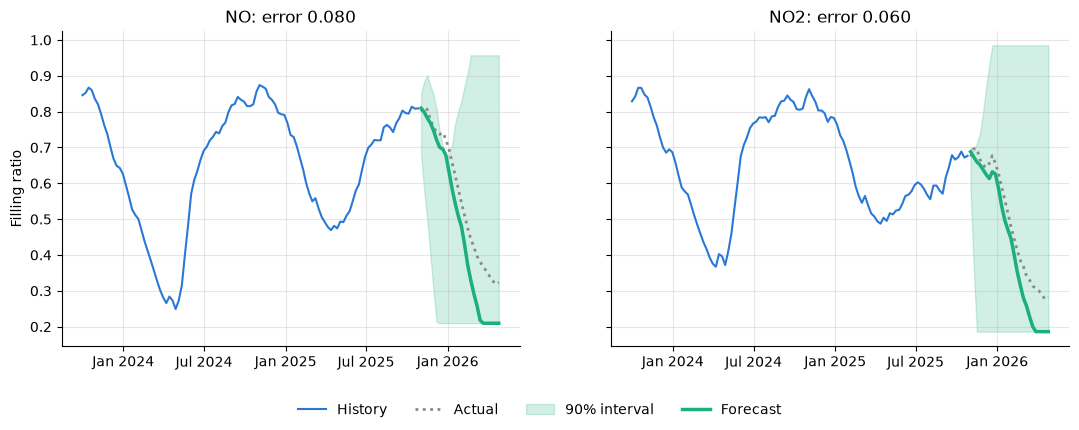

In [23]:
# Example with the default setting: Norway and NO2, training until the end of October 2025
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, region in zip(axes, ["NO", "NO2"]):
    r = forecast_filling(region, "2025-10-26", interval=True, **default_settings)
    history = filling[region]["2023-10-01":"2025-10-26"]
    ax.plot(history.index, history, color=BLUE, label="History")
    ax.plot(r.index, r["actual"], color=GREY, linestyle=":", linewidth=2, label="Actual")
    ax.fill_between(r.index, r["lower"], r["upper"], color=GREEN, alpha=0.2, label="90% interval")
    ax.plot(r.index, r["forecast"], color=GREEN, linewidth=2.5, label="Forecast")
    ax.set_title(f"{region}: error {(r['forecast'] - r['actual']).abs().mean():.3f}")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].set_ylabel("Filling ratio")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.subplots_adjust(bottom=0.18)
plt.show()

In [24]:
# Mean error per forecast origin (default setting, all 9 areas)
per_origin = {}
for origin in ORIGINS:
    errors = [(r["forecast"] - r["actual"]).abs().mean()
              for r in (forecast_filling(region, origin, **default_settings) for region in filling)]
    per_origin[origin] = np.mean(errors)
pd.Series(per_origin, name="mean error").round(4)

2022-10-30    0.0685
2023-10-29    0.0534
2024-10-27    0.0539
2025-04-27    0.1273
Name: mean error, dtype: float64

Both example forecasts follow the start of the winter well, but then fall faster than the actual filling
and end at the lower limit (the lowest filling in the training data). The model continues the drawdown
from the autumn, and it does not know that the producers save water when the reservoirs get low.
Forecasts made at the end of April are even harder (about twice the error of the October forecasts):
how fast the reservoirs fill up depends on the amount of snow and on the summer weather to come, which
the model only knows as an average.

**Default in the app:** SNARIMAX(2, 1, 0)(1, 1, 0) with a season of 52 weeks, 10 years of history,
learning rate 0.01, season features and precipitation, 26 weeks ahead (`forecasting.DEFAULTS`). All
parameters, the history, the horizon and the inputs can be changed on the Forecast page.

## 8. Sketch of the app structure

The structure of the app: a front page and three groups of pages
(Explore, Patterns & anomalies, Predict), which controls are global (area, set in the sidebar or by
clicking on the map; the map month, used by the forecast) and which are local, and which data source
each page uses.

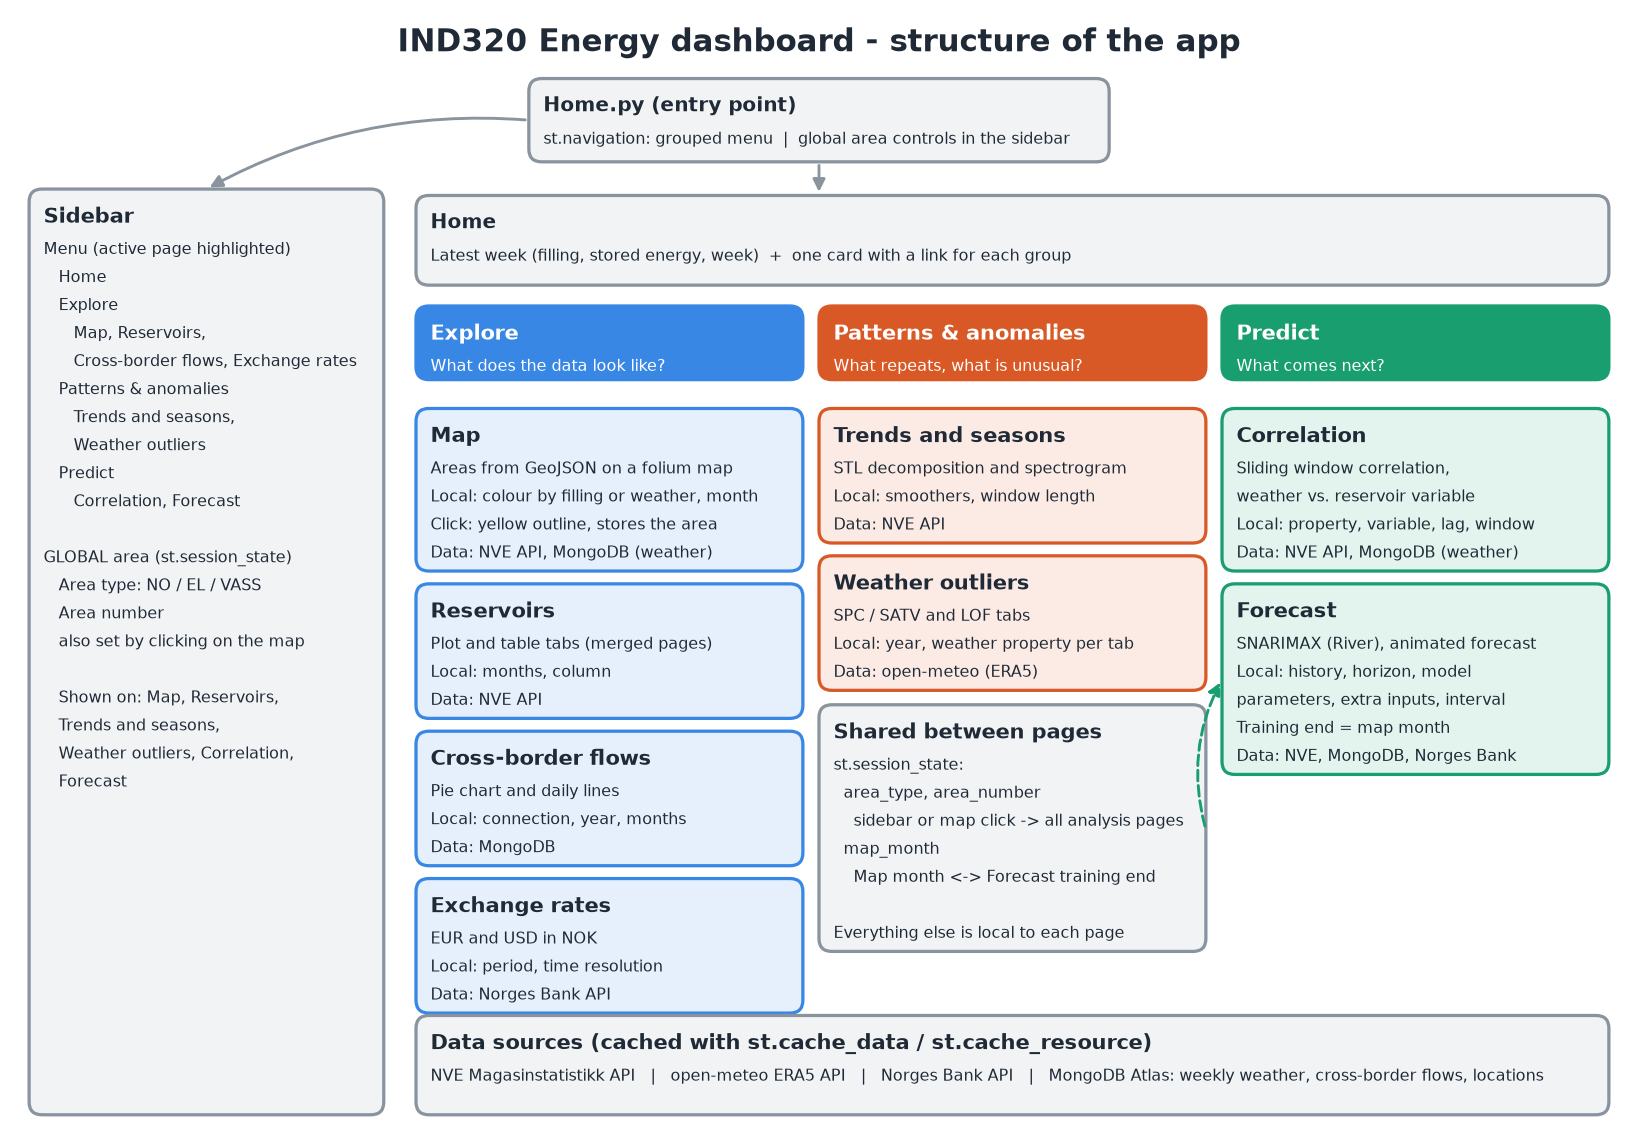

In [25]:
display(Image(filename=ROOT / "notebooks" / "app_sketch.png", width=900))

In [26]:
client.close()